<a href="https://colab.research.google.com/github/akshaybhatt97/365-DAYS-AI-ML-WITH-AKSHAY/blob/main/day_084_activation_functions.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Day 84/365 — Activation Functions

## Interview question
**Why do neural networks need activation functions, and when do we use ReLU, Sigmoid, Tanh, or Softmax?**

Yesterday we learned forward propagation:

`z = Wx + b`

An activation function transforms that weighted sum:

`a = f(z)`

Without nonlinear activation functions, stacking many layers would still collapse into an overall linear transformation.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


## 1. Define the four activations

In [2]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def tanh(z):
    return np.tanh(z)

def relu(z):
    return np.maximum(0, z)

def softmax(z):
    z = np.array(z, dtype=float)
    exp_z = np.exp(z - np.max(z))
    return exp_z / exp_z.sum()


## 2. Same input, different outputs

Let:

`z = 2`

Then each activation transforms the same number differently.


In [3]:
z = 2.0

print("Sigmoid:", round(sigmoid(z), 3))
print("Tanh:", round(tanh(z), 3))
print("ReLU:", round(float(relu(z)), 3))


Sigmoid: 0.881
Tanh: 0.964
ReLU: 2.0


For `z = 2`:

- Sigmoid ≈ `0.881`
- Tanh ≈ `0.964`
- ReLU = `2`


## 3. Plot Sigmoid, Tanh and ReLU

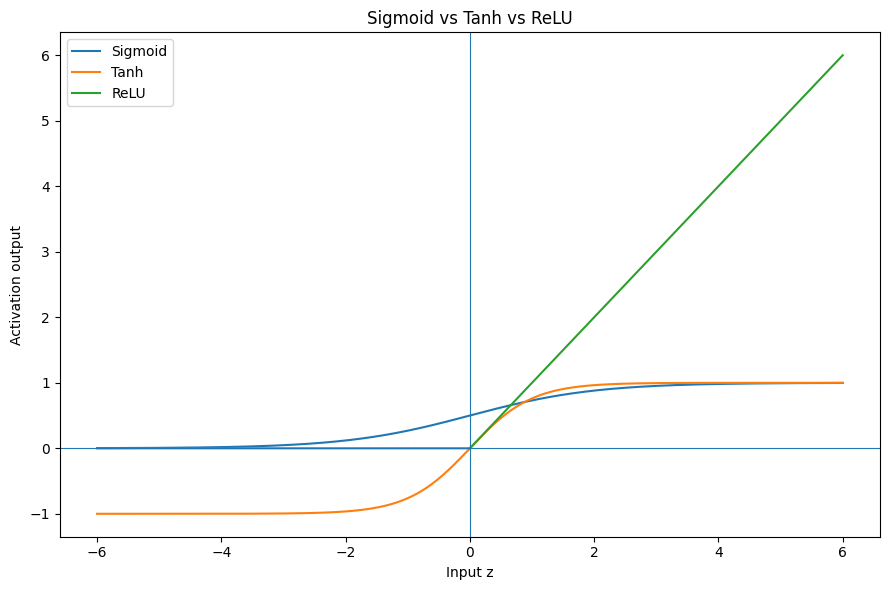

In [4]:
x = np.linspace(-6, 6, 400)

plt.figure(figsize=(9,6))
plt.plot(x, sigmoid(x), label="Sigmoid")
plt.plot(x, tanh(x), label="Tanh")
plt.plot(x, relu(x), label="ReLU")
plt.axhline(0, linewidth=0.8)
plt.axvline(0, linewidth=0.8)
plt.xlabel("Input z")
plt.ylabel("Activation output")
plt.title("Sigmoid vs Tanh vs ReLU")
plt.legend()
plt.tight_layout()
plt.show()


## 4. Sigmoid

Formula:

`σ(z) = 1 / (1 + e^-z)`

Range:

`0 to 1`

Typical use:

**Binary-classification output layer**

A value like `0.91` can be interpreted as a model probability for the positive class.

### Limitation
At very large positive or negative values, the gradient becomes tiny.

This contributes to the **vanishing-gradient problem**.


## 5. Tanh

Range:

`-1 to 1`

Tanh is zero-centered and historically appeared often in hidden layers.

It remains important inside recurrent architectures such as LSTM/GRU.

It can still saturate and suffer from vanishing gradients.


## 6. ReLU

Formula:

`ReLU(z) = max(0, z)`

Examples:

`ReLU(-3) = 0`

`ReLU(4) = 4`

ReLU is a common hidden-layer activation because it is simple and does not saturate on the positive side.


In [5]:
values = np.array([-3, -1, 0, 1, 3])

pd.DataFrame({
    "z": values,
    "ReLU(z)": relu(values)
})


,z,ReLU(z)
0,-3,0
1,-1,0
2,0,0
3,1,1
4,3,3


### ReLU limitation: dying ReLU

For negative inputs, ReLU outputs zero.

A neuron that repeatedly stays on the negative side can stop learning.

Popular variants include:

- Leaky ReLU
- PReLU
- GELU

GELU is especially important in modern Transformer architectures.


## 7. Softmax

Softmax is typically used for **mutually exclusive multiclass classification**.

Suppose the model produces logits:

`[2.0, 1.0, 0.1]`

Softmax converts them into probabilities that sum to 1.


In [6]:
logits = [2.0, 1.0, 0.1]

probs = softmax(logits)

print("Probabilities:", probs)
print("Sum:", probs.sum())


Probabilities: [0.65900114 0.24243297 0.09856589]
Sum: 1.0


## 8. Sigmoid vs Softmax — common interview question

### Binary classification
One output neuron → **Sigmoid**

### Mutually exclusive multiclass classification
Multiple class outputs → **Softmax**

### Multilabel classification
Several labels may be true at once → independent **Sigmoid** outputs

Softmax makes classes compete because probabilities sum to 1.


## 9. Why nonlinearity matters

If every layer used only:

`a = Wx + b`

then several layers would still combine into another linear/affine transformation.

So simply stacking linear layers does not give a neural network true nonlinear modeling power.

Activation functions break that linearity.


## 10. Interview cheat sheet

| Activation | Range | Typical Use | Main Issue |
|---|---|---|---|
| Sigmoid | 0 to 1 | Binary output | Vanishing gradient |
| Tanh | -1 to 1 | RNN-style hidden states | Saturation |
| ReLU | 0 to ∞ | Hidden layers | Dying ReLU |
| Softmax | Probabilities sum to 1 | Multiclass output | Classes must compete |


## Enterprise intuition

Imagine a neural network scoring a transaction.

Hidden layers may use **ReLU** for nonlinear representation learning.

If the final task is:

**Fraud vs Genuine**

the output may use **Sigmoid**.

If the task is:

**Class A vs Class B vs Class C**

the output may use **Softmax**.

The activation depends on what the layer is meant to represent.


## What does this teach?

- Activation functions introduce nonlinearity.
- Sigmoid maps values to 0–1.
- Tanh maps values to -1–1.
- ReLU is a common hidden-layer default.
- Softmax converts multiclass logits into probabilities that sum to 1.
- Multilabel outputs typically use independent Sigmoid activations.
- Saturating activations can cause vanishing gradients.
- ReLU can suffer from dying neurons.

> **Weights decide what signal to combine. Activation functions decide how that signal is allowed to flow forward.**


## References

- Deep Learning — Goodfellow, Bengio & Courville:
  https://www.deeplearningbook.org/

- Stanford CS231n — Neural Networks:
  https://cs231n.github.io/neural-networks-1/

- PyTorch — Non-linear activations:
  https://pytorch.org/docs/stable/nn.functional.html#non-linear-activation-functions

- TensorFlow / Keras Activations:
  https://www.tensorflow.org/api_docs/python/tf/keras/activations
